# RLHF end to end: a learned reward model and PPO on GPT-2

This notebook runs the whole *reinforcement learning from human feedback* pipeline on one GPU, top to bottom:

```
                     ┌─► 2. SFT: fine-tune GPT-2 on reviews ──┐
 IMDB reviews ─► 1. ─┤                                        ├─► 4. PPO ─► 5. Evaluation
 (half negative)     └─► 3. Reward model from preferences ────┘
```

1. **Data.** IMDB movie reviews: 25,000 labeled positive or negative by their authors, plus 50,000 unlabeled.
2. **Supervised fine-tuning (SFT).** Pretrained GPT-2 learns to write movie reviews. It writes positive and
   negative ones about equally often, because that is what the data looks like.
3. **Reward model.** A second network learns a score $r(x)$ from *preference pairs*: "this text is preferred over
   that one". Here a positive review is preferred over a negative one, so the labels play the role of the human
   annotators.
4. **PPO.** The fine-tuned model becomes a *policy*. It writes continuations, the reward model scores them, and
   PPO shifts the policy toward higher scores, while a KL penalty keeps it close to the SFT model.
5. **Evaluation.** Before and after, on prompts nothing was trained on, judged by a sentiment classifier that the
   policy never saw.

### What is different from `minimal-rlhf`

| | `minimal-rlhf` | this notebook |
|---|---|---|
| Data | TinyStories, 90% already positive | IMDB, 50% positive, so there is something to steer |
| Model | 0.8M-parameter character model from scratch | pretrained GPT-2 (124M) |
| Reward | VADER word lexicon | a network trained on preference pairs |
| RL update | one REINFORCE step per batch | PPO: value function, GAE, clipped objective, several epochs per batch |
| Evaluation | the training reward on the training prompt | held-out prompts and an independent judge |

Every stage saves its result in `out/`. Running the notebook again loads those results, and a stage retrains
only when its settings changed.

## 0. Setup

All settings live in the `CFG` dictionary below. Three things to know before running:

- **Run All takes about half an hour on one A100.** Each stage saves its result in `out/`. On the next run a stage
  is loaded from there if its settings are unchanged, so re-running the notebook only repeats what you changed.
  To force a stage to retrain, delete its file in `out/`.
- **Without a GPU the notebook switches to smoke mode:** a few hundred reviews and three PPO iterations, enough
  to check that every cell runs (a few minutes on a laptop). Smoke results go to `out_smoke/` and mean nothing.
- **Settings can be overridden without editing the notebook** through the `RLHF_CFG` environment variable, for
  example `RLHF_CFG='{"ppo_kl_target": 3}'`. Batch jobs use this to try variations.

In [1]:
import contextlib, html, json, math, os, re, sys, textwrap, time, warnings
from collections import defaultdict
from pathlib import Path

ROOT = Path.cwd()
os.environ.setdefault("HF_HOME", str(ROOT / "hf_cache"))      # keep downloads next to the notebook, off the home quota
os.environ.setdefault("TOKENIZERS_PARALLELISM", "true")

warnings.filterwarnings("ignore", message=".*IProgress not found.*")   # progress bars are switched off below

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import datasets, transformers
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, GPT2LMHeadModel, GPT2Model

transformers.logging.set_verbosity_error()
with contextlib.suppress(Exception):
    datasets.disable_progress_bars()
    datasets.utils.logging.set_verbosity_error()
    transformers.utils.logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
device = os.environ.get("RLHF_DEVICE", device)
SMOKE = os.environ.get("RLHF_SMOKE", "0" if device == "cuda" else "1") == "1"   # tiny run when there is no GPU

CFG = dict(
    seed=0,
    model_name="openai-community/gpt2",
    judge_name="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    prompt_len=8,                  # P: tokens of a real review that the policy is given
    gen_len=56,                    # T: tokens the policy writes
    max_reviews=None,              # cap on reviews per split (smoke mode only)
    n_sft_val=1000, n_eval=2000, n_dev=256,
    # stage 2: supervised fine-tuning
    sft_len=128, sft_batch=64, sft_epochs=2, sft_max_steps=None, sft_lr=5e-5, sft_warmup=100, sft_wd=0.01,
    # stage 3: reward model
    rm_max_len=512, rm_steps=1000, rm_batch=64, rm_lr=2e-5, rm_warmup=60, rm_wd=0.01, rm_opening_frac=0.5,
    calib_n=4096,                  # SFT samples used to normalise the reward and to warm up the critic
    # stage 4: PPO
    ppo_iters=60, ppo_batch=512, ppo_minibatch=128, ppo_epochs=4, ppo_clip=0.2,
    ppo_policy_lr=1e-5, ppo_critic_lr=3e-5, ppo_gamma=1.0, ppo_lam=0.95, ppo_grad_clip=1.0,
    ppo_kl_target=6.0,             # KL budget in nats per sequence; None keeps beta fixed
    ppo_beta_init=0.1, ppo_beta_rate=0.2, ppo_beta_min=0.01, ppo_beta_max=10.0,
    ppo_step_kl=0.02,              # stop an iteration's remaining epochs past this KL(old || new) per token
    ppo_critic_warmup_epochs=2, ppo_eval_every=5,
    # stage 5: evaluation
    eval_boot=1000,
)
if SMOKE:
    CFG.update(max_reviews=1500, n_sft_val=64, n_eval=64, n_dev=32, sft_batch=8, sft_epochs=1, sft_max_steps=30,
               sft_warmup=5, rm_steps=30, rm_batch=8, rm_warmup=3, calib_n=64, ppo_iters=3, ppo_batch=32,
               ppo_minibatch=16, ppo_epochs=2, ppo_critic_warmup_epochs=1, ppo_eval_every=1, eval_boot=200)
overrides = json.loads(os.environ.get("RLHF_CFG", "{}"))      # e.g. RLHF_CFG='{"ppo_kl_target": 8}'
assert set(overrides) <= set(CFG), f"unknown settings: {set(overrides) - set(CFG)}"
CFG.update(overrides)

OUT = ROOT / ("out_smoke" if SMOKE else "out")
(OUT / "plots").mkdir(parents=True, exist_ok=True)
AMP = device == "cuda"                                        # bf16 for the transformer trunk in stages 2 and 3
torch.manual_seed(CFG["seed"])
np.random.seed(CFG["seed"])
print(f"device={device}  SMOKE={SMOKE}  torch={torch.__version__}  transformers={transformers.__version__}  out={OUT.name}/")
if device == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB")

device=cuda  SMOKE=False  torch=2.14.1+cu130  transformers=5.24.1  out=out/
NVIDIA A100 80GB PCIe 79 GB


In [2]:
# Stage cache: a stage's result is reused only if it was produced with exactly the same settings.
BASE_KEYS = ("seed", "model_name", "prompt_len", "gen_len", "max_reviews", "n_sft_val", "n_eval", "n_dev")
TIMES = {}


def settings_for(*prefixes):
    return {k: v for k, v in CFG.items() if k in BASE_KEYS or k.startswith(prefixes)}


def cached(name, settings, build):
    path = OUT / f"{name}.pt"
    if path.exists():
        ck = torch.load(path, map_location="cpu", weights_only=True)
        if ck["settings"] == settings:
            print(f"[{name}] loaded from {path.relative_to(ROOT)}")
            TIMES[name] = ck["seconds"]
            return ck
        print(f"[{name}] {path.name} was built with different settings, rebuilding")
    t0 = time.time()
    ck = {"settings": settings, **build()}
    ck["seconds"] = time.time() - t0
    tmp = path.with_suffix(".tmp")
    torch.save(ck, tmp)
    os.replace(tmp, path)
    TIMES[name] = ck["seconds"]
    print(f"[{name}] done in {ck['seconds'] / 60:.1f} min, saved to {path.relative_to(ROOT)}")
    return ck


def cpu_state(module):
    return {k: v.detach().cpu().clone() for k, v in module.state_dict().items()}


def autocast(on):
    return torch.autocast("cuda", dtype=torch.bfloat16) if (on and device == "cuda") else contextlib.nullcontext()

In [3]:
# Plot style: one colour per thing, used the same way in every figure.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
COLOR = {"SFT": "#2a78d6", "PPO": "#eb6834", "GPT-2": "#1baf7a", "Human": MUTED,
         "positive": "#2a78d6", "negative": "#e34948", "train": "#2a78d6", "validation": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "axes.labelsize": 9.5, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "sans-serif", "font.size": 10, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round", "legend.frameon": False, "legend.fontsize": 9,
})


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / "plots" / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show() if IN_NOTEBOOK else plt.close(fig)


def reference_line(ax, y, label, x=0.99):
    """A thin horizontal marker with its label written on it."""
    ax.axhline(y, color=MUTED, lw=1, zorder=1)
    ax.annotate(label, (x, y), xycoords=("axes fraction", "data"), ha="right", va="bottom", fontsize=8, color=INK2,
                xytext=(0, 2), textcoords="offset points", bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.2, alpha=0.9))


def show_table(df):
    display(df) if IN_NOTEBOOK else print(df.to_string())     # noqa: F821  (display exists in notebooks)

## 1. Data

Each IMDB split gets exactly one job, so nothing leaks from the stage that *learns* the reward into the stage
that is *evaluated*:

| Split | Size | Used for |
|---|---|---|
| `unsupervised` | 50,000, no labels | fine-tuning the language model, and prompts for PPO rollouts |
| `train` | 25,000 labeled | preference pairs for the reward model (90% train, 10% validation) |
| `test` | 25,000 labeled | held-out prompts for evaluation only |

### One sequence layout for the whole notebook

Every episode has the same shape: a start token, the first `P = 8` tokens of a real review as the prompt, then
`T = 56` tokens written by the policy (about 40 words).

```
index:    0       1 … P          P+1 … P+T
token:  [BOS]   prompt          continuation            L = 1 + P + T = 65
```

Because every sequence has exactly this shape there is no padding and no mask anywhere in the RL code. GPT-2
has a single special token, `<|endoftext|>`. It serves as `[BOS]` here and is removed from the set of tokens
the policy may write, so episodes always run for exactly `T` steps.

In [4]:
tok = AutoTokenizer.from_pretrained(CFG["model_name"])
EOS = tok.eos_token_id                      # 50256, used as [BOS]; never generated
assert EOS == len(tok) - 1                  # it is the last id, so `logits[..., :EOS]` removes it from the action space
P, T = CFG["prompt_len"], CFG["gen_len"]
L = 1 + P + T


def clean(text):
    text = html.unescape(re.sub(r"<br\s*/?>", " ", text))
    return re.sub(r"\s+", " ", text).strip()


def encode(texts, max_len):
    rows = tok(texts, truncation=True, max_length=max_len)["input_ids"]
    return [[t for t in r if t != EOS] if EOS in r else r for r in rows]


def pad_rows(rows, width):
    out = torch.full((len(rows), width), EOS, dtype=torch.long)
    for i, r in enumerate(rows):
        out[i, :len(r)] = torch.tensor(r, dtype=torch.long)
    return out


t0 = time.time()
raw = load_dataset("stanfordnlp/imdb")
rng = np.random.default_rng(CFG["seed"])
seen, data = set(), {}
for split in ("test", "train", "unsupervised"):               # a review that appears twice stays in the earlier split
    rows = raw[split][:]
    texts, labels = [], []
    for text, label in zip(rows["text"], rows["label"]):
        text = clean(text)
        if text not in seen:
            seen.add(text)
            texts.append(text)
            labels.append(label)
    order = rng.permutation(len(texts))[:CFG["max_reviews"]]  # the labeled splits are stored sorted by label
    data[split] = ([texts[i] for i in order], np.array(labels)[order])
print("reviews after removing duplicates:", {k: len(v[0]) for k, v in data.items()})

# --- unlabeled reviews: language-model fine-tuning and PPO prompts
unsup = encode(data["unsupervised"][0], CFG["sft_len"] - 1)
sft_all = pad_rows([[EOS] + r for r in unsup], CFG["sft_len"])            # [BOS] + first 127 tokens, right-padded
sft_all_len = torch.tensor([len(r) for r in unsup])                       # number of real text tokens per row
nv = CFG["n_sft_val"]
sft_val, sft_val_len, sft_train, sft_train_len = sft_all[:nv], sft_all_len[:nv], sft_all[nv:], sft_all_len[nv:]
prompt_pool = sft_train[sft_train_len >= P][:, :1 + P]                    # [BOS] + first P tokens

# --- labeled train reviews: reward-model preference pairs
ids = encode(data["train"][0], CFG["rm_max_len"])
keep = [i for i, r in enumerate(ids) if len(r) >= L - 1]
rm_tokens = pad_rows([ids[i] for i in keep], CFG["rm_max_len"])
rm_len = torch.tensor([len(ids[i]) for i in keep])
rm_label = torch.tensor(data["train"][1][keep])
pos_rows, neg_rows = (rm_label == 1).nonzero().squeeze(1), (rm_label == 0).nonzero().squeeze(1)
n_val = max(4, len(keep) // 20)                                            # 10% of the reviews, half from each class
rm_val_rows = torch.cat([pos_rows[:n_val], neg_rows[:n_val]])
pos_rows, neg_rows = pos_rows[n_val:], neg_rows[n_val:]

# --- labeled test reviews: held-out prompts (and their real openings, for the "human" row of the results)
ids = encode(data["test"][0], L - 1)
full = [i for i, r in enumerate(ids) if len(r) == L - 1]
test_neg = [i for i in full if data["test"][1][i] == 0]
test_pos = [i for i in full if data["test"][1][i] == 1]
h, d = CFG["n_eval"] // 2, CFG["n_dev"] // 2
assert min(len(test_neg), len(test_pos)) >= h + d
eval_seq = torch.tensor([[EOS] + ids[i] for i in test_neg[:h] + test_pos[:h]])           # (n_eval, L)
eval_label = torch.tensor([0] * h + [1] * h)
dev_seq = torch.tensor([[EOS] + ids[i] for i in test_neg[h:h + d] + test_pos[h:h + d]])  # used to watch PPO train
eval_prompts, dev_prompts = eval_seq[:, :1 + P], dev_seq[:, :1 + P]
watch = dev_prompts[[0, d, 1]]                                                            # three prompts to print

TIMES["data"] = time.time() - t0
print(f"SFT: {len(sft_train):,} train / {len(sft_val):,} val sequences of {CFG['sft_len']} tokens")
print(f"reward model: {len(pos_rows):,} positive + {len(neg_rows):,} negative train reviews, {len(rm_val_rows):,} validation")
print(f"PPO prompt pool: {len(prompt_pool):,}   eval prompts: {len(eval_prompts):,}   dev prompts: {len(dev_prompts):,}")
print(f"\nexample prompt:        {tok.decode(eval_seq[0, 1:1 + P].tolist())!r}")
print(f"its real continuation: {tok.decode(eval_seq[0, 1 + P:].tolist())!r}")

reviews after removing duplicates: {'test': 24799, 'train': 24779, 'unsupervised': 48885}


SFT: 47,885 train / 1,000 val sequences of 128 tokens
reward model: 10,867 positive + 10,877 negative train reviews, 2,416 validation
PPO prompt pool: 47,885   eval prompts: 2,000   dev prompts: 256

example prompt:        'Believe it or not, this was'
its real continuation: ' at one time the worst movie I had ever seen. Since that time, I have seen many more movies that are worse (how is it possible??) Therefore, to be fair, I had to give this movie a 2 out of 10. But it was a tough call.'


## Model building blocks

Three small pieces are used by every stage.

**The policy's distribution** is defined in one place, `next_token_logits`: GPT-2's logits with the
`<|endoftext|>` column sliced off. Fine-tuning, sampling, PPO and evaluation all go through it, so the
distribution that is *sampled from* is always the distribution that is *scored*. Sampling uses temperature 1
with no top-k. (`minimal-rlhf` sampled with top-k = 30 but computed log-probabilities under the full softmax,
which are two different distributions.)

**`generate`** samples continuations with key-value caching: the prompt is run once, then each new token costs
one single-token forward pass.

**`ScalarGPT`** is a GPT-2 trunk with a linear head that outputs one number per position. It is used twice:
as the reward model (read the number at the last position) and as PPO's critic (read the number at every
position where an action is taken).

A note on precision: GPT-2's logits are large in magnitude (around −100), where 16-bit floats are spaced 0.5
apart. Rounding logits to bf16 changes log-probabilities by about 0.1 nats per token, which is far too coarse
for PPO's probability ratios. So the output head always runs in 32-bit, and the PPO stage runs entirely in
32-bit. Only the transformer trunk uses bf16, and only in stages 2 and 3.

In [5]:
def new_lm(state=None):
    lm = GPT2LMHeadModel.from_pretrained(CFG["model_name"])
    if state is not None:
        lm.load_state_dict(state)
    return lm.to(device).eval()


def next_token_logits(lm, ids, amp=False):
    """ids (B, n) -> logits over the next token at every position, (B, n, V-1). The head runs in fp32."""
    with autocast(amp):
        hidden = lm.transformer(ids).last_hidden_state
    return lm.lm_head(hidden.float())[..., :EOS]


def action_logprobs(lm, seq):
    """seq (B, L) -> log-probability of each generated token (B, T), and the full table (B, T, V-1).

    The hidden state at index j predicts the token at index j+1. The generated tokens sit at indices
    P+1 … P+T, so their distributions come from indices P … P+T-1 of the input seq[:, :-1].
    """
    hidden = lm.transformer(seq[:, :-1]).last_hidden_state[:, P:]
    table = F.log_softmax(lm.lm_head(hidden)[..., :EOS], dim=-1)
    return table.gather(-1, seq[:, P + 1:, None]).squeeze(-1), table


@torch.no_grad()
def generate(lm, prompts, n_new=T, generator=None, batch=512):
    """Sample n_new tokens after each prompt. Returns the sequences and the log-prob of every sampled token."""
    assert not lm.training
    seqs, logps = [], []
    for chunk in prompts.split(batch):
        chunk = chunk.to(device)
        out = lm.transformer(chunk, use_cache=True)
        new, lp = [], []
        for t in range(n_new):
            logp = F.log_softmax(lm.lm_head(out.last_hidden_state[:, -1])[:, :EOS], dim=-1)
            action = torch.multinomial(logp.exp(), 1, generator=generator)
            new.append(action)
            lp.append(logp.gather(-1, action))
            if t + 1 < n_new:
                out = lm.transformer(action, cache=out.cache, use_cache=True)
        seqs.append(torch.cat([chunk] + new, dim=1))
        logps.append(torch.cat(lp, dim=1))
    return torch.cat(seqs), torch.cat(logps)


class ScalarGPT(nn.Module):
    """GPT-2 trunk + linear head: one number per position."""

    def __init__(self):
        super().__init__()
        self.trunk = GPT2Model.from_pretrained(CFG["model_name"])
        self.head = nn.Linear(self.trunk.config.n_embd, 1)
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def forward(self, ids, amp=False):
        with autocast(amp):
            hidden = self.trunk(ids).last_hidden_state
        return self.head(hidden.float()).squeeze(-1)


def reward_of(rm, seq, amp=False):
    """Reward-model score of each full sequence: the head's output at the last position. (B, L) -> (B,)"""
    return rm(seq, amp)[:, -1]


def values_of(critic, seq):
    """Critic's value of the state before each action: positions P … P+T-1. (B, L) -> (B, T)"""
    return critic(seq[:, :-1])[:, P:]


@torch.no_grad()
def in_chunks(fn, seq, batch=256):
    return torch.cat([fn(chunk.to(device)) for chunk in seq.split(batch)])


def gen_for(seed):
    return torch.Generator(device=device).manual_seed(CFG["seed"] + seed)


def to_text(seq):
    return tok.batch_decode(seq[:, 1:].tolist())               # drop [BOS]


def show_samples(lm, title, seed=7):
    seq, _ = generate(lm, watch, generator=gen_for(seed))
    print(f"--- {title}")
    for row in seq.tolist():
        print(textwrap.fill(f"[{tok.decode(row[1:1 + P])}]{tok.decode(row[1 + P:])}", 118, subsequent_indent="    "))


def lr_at(step, total, warmup, base):
    """Linear warm-up, then cosine decay to 10% of the base rate."""
    if step < warmup:
        return base * (step + 1) / warmup
    return base * (0.1 + 0.45 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup))))

## 2. Supervised fine-tuning

Pretrained GPT-2 has read the internet, not specifically movie reviews. Two passes of ordinary next-token
training over the unlabeled reviews give a model that writes like an IMDB reviewer:

$$\mathcal{L}_\text{SFT}(\theta) = -\,\mathbb{E}_{x \sim \text{reviews}} \sum_t \log \pi_\theta(x_t \mid x_{<t})$$

This model matters twice later on. It is the **starting policy** for PPO, and a frozen copy of it is the
**reference** $\pi_\text{ref}$ that the KL penalty measures distance from.

No labels are used here, so the model has no preference between positive and negative reviews. Unlike
TinyStories, about half of what it writes will be negative.

validation loss of pretrained GPT-2: 3.829 nats/token


--- pretrained GPT-2
[Princess Warrior is a science fiction action] RPG, where two powerful warriors stealth throughout a battle by
    following a leader's orders.  One or more submarines are present along with other remaining submarines and
    powerful machines are patrolling the beach and food is provided for the soldiers. A complex nationwide array of
    training and technology is provided
[Dario Argento is a filmmaker I]'ve been intrigued byi'm starting to publish a podcast next month called "aintain and
    uphold your privilege – 99 percent of the time" that pretty much a bunch of people at IGN stand by. Check it out,
    or download it here, it's just free to listen now
[This...... Movie.... Is..... Horrible] but pleasantly...iladon....... Now thru2014 Daisuke Tojo 07 RUN IMMEDIATELY
    Top 80 Different Releases -----------------------------777 AVAILABLE AT Yazoo ga Shunsurugi , 175 G-Force Vol.
    8043676 MKII Crosley


step   250/1496  train 3.789  val 3.675


step   500/1496  train 3.740  val 3.644


step   750/1496  train 3.708  val 3.624


step  1000/1496  train 3.657  val 3.615


step  1250/1496  train 3.650  val 3.611


step  1496/1496  train 3.629  val 3.607


--- after fine-tuning
[Princess Warrior is a science fiction action] film, where two twin boys stealthily rule battle through a dangerous
    desert environment, although the monsters and orations left behind are actually quite serious science fiction and
    that they are not capable of a real-world effort - nor will they be portrayed with a straight face until they
    destroy one
[Dario Argento is a filmmaker I]'ve been intrigued byi'm starting to watch a lot.and it's not worth the delay.but I
    poked around at Argento's movies pretty extensively a while ago i saw a lot of him. _tactical_ were who t wanted
    to acquire them. _end
[This...... Movie.... Is..... Horrible]. I knew Legion of Blood would be thru. But I kept waiting. IT RUNS FOR TIME!
    It seems like they didn't put the character creators in the movie to make it like Legion of Blood , etc. Who knew
    that almost 90% of violence scenes are in this


[sft] done in 6.4 min, saved to out/sft.pt
validation loss: 3.829 (pretrained) -> 3.607 (fine-tuned) nats/token, perplexity 46.0 -> 36.8


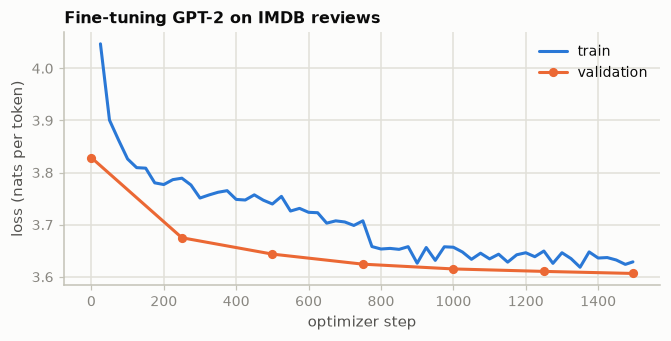

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [6]:
def lm_loss(lm, ids, n_tokens, amp=False):
    """Mean next-token cross-entropy over the real (unpadded) tokens. ids (B, n) starts with [BOS]."""
    logits = next_token_logits(lm, ids[:, :-1], amp)
    targets = ids[:, 1:].clone()
    targets[torch.arange(targets.shape[1], device=ids.device)[None] >= n_tokens[:, None]] = -100
    return F.cross_entropy(logits.flatten(0, 1), targets.flatten(), ignore_index=-100)


@torch.no_grad()
def lm_val_loss(lm):
    was_training = lm.training
    lm.eval()
    total = count = 0
    for i in range(0, len(sft_val), 64):
        ids, n = sft_val[i:i + 64].to(device), sft_val_len[i:i + 64].to(device)
        total += lm_loss(lm, ids, n).item() * n.sum().item()
        count += n.sum().item()
    lm.train(was_training)
    return total / count


def build_sft():
    lm = new_lm()
    history = {"step": [], "train": [], "val_step": [0], "val": [lm_val_loss(lm)]}
    print(f"validation loss of pretrained GPT-2: {history['val'][0]:.3f} nats/token")
    show_samples(lm, "pretrained GPT-2")
    lm.train()
    opt = torch.optim.AdamW(lm.parameters(), lr=CFG["sft_lr"], weight_decay=CFG["sft_wd"])
    g = torch.Generator().manual_seed(CFG["seed"])
    per_epoch = len(sft_train) // CFG["sft_batch"]
    total = min(CFG["sft_epochs"] * per_epoch, CFG["sft_max_steps"] or 10**9)
    step, running = 0, []
    while step < total:
        for rows in torch.randperm(len(sft_train), generator=g).split(CFG["sft_batch"])[:per_epoch]:
            for group in opt.param_groups:
                group["lr"] = lr_at(step, total, CFG["sft_warmup"], CFG["sft_lr"])
            loss = lm_loss(lm, sft_train[rows].to(device), sft_train_len[rows].to(device), AMP)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(lm.parameters(), 1.0)
            opt.step()
            running.append(loss.item())
            step += 1
            if step % 25 == 0 or step == total:
                history["step"].append(step)
                history["train"].append(float(np.mean(running)))
                running = []
            if step % 250 == 0 or step == total:
                history["val_step"].append(step)
                history["val"].append(lm_val_loss(lm))
                print(f"step {step:5d}/{total}  train {history['train'][-1]:.3f}  val {history['val'][-1]:.3f}")
            if step == total:
                break
    lm.eval()
    show_samples(lm, "after fine-tuning")
    return {"model": cpu_state(lm), "history": history}


sft_ck = cached("sft", settings_for("sft_"), build_sft)
hist = sft_ck["history"]
print(f"validation loss: {hist['val'][0]:.3f} (pretrained) -> {hist['val'][-1]:.3f} (fine-tuned) nats/token, "
      f"perplexity {math.exp(hist['val'][0]):.1f} -> {math.exp(hist['val'][-1]):.1f}")

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.plot(hist["step"], hist["train"], color=COLOR["train"], label="train")
ax.plot(hist["val_step"], hist["val"], color=COLOR["validation"], marker="o", ms=5, label="validation")
ax.set(title="Fine-tuning GPT-2 on IMDB reviews", xlabel="optimizer step", ylabel="loss (nats per token)")
ax.legend()
finish(fig, "sft")

# The frozen reference policy. It is never trained again.
ref = new_lm(sft_ck["model"])
ref.requires_grad_(False)

## 3. Reward model

In RLHF nobody writes the reward function. Annotators compare two outputs and say which they prefer, and a
network learns a score that agrees with them. The standard model for this is **Bradley-Terry**: the
probability that $a$ is preferred over $b$ is a logistic function of the difference of their scores,

$$P(a \succ b) = \sigma\big(r_\phi(a) - r_\phi(b)\big), \qquad
  \mathcal{L}_\text{RM}(\phi) = -\,\mathbb{E}_{(a \succ b)} \log \sigma\big(r_\phi(a) - r_\phi(b)\big).$$

Only *differences* of scores matter, so the scale and zero point of $r_\phi$ are arbitrary. They are fixed
afterwards by normalization.

**Where the preferences come from.** Each IMDB review was labeled positive or negative by the person who wrote
it. A pair is one positive text and one negative text, with the positive one preferred. The pairing is redrawn
at random every step.

**What text the pairs contain.** The reward model will be asked to score 64-token sequences that start like a
review opening. A model trained on whole reviews (about 300 tokens) would be judging something it never saw.
So it trains on 64-token windows in exactly the PPO layout, `[BOS]` + 64 tokens: half of them review openings,
half cut from a random place in the review for variety.

**Architecture.** A GPT-2 trunk with a linear head on the last token's hidden state. With a causal model the
last position is the only one that has seen the whole text. The head starts at zero, so the first loss must
be exactly $\ln 2 \approx 0.693$ (the model is indifferent between the two texts), which is asserted.

In [7]:
def sample_windows(rows, g, opening_frac):
    """One (L-1)-token window per review, with [BOS] in front: (n,) -> (n, L)."""
    start = (torch.rand(len(rows), generator=g) * (rm_len[rows] - (L - 1) + 1)).long()
    start[torch.rand(len(rows), generator=g) < opening_frac] = 0
    window = rm_tokens[rows[:, None], start[:, None] + torch.arange(L - 1)]
    return torch.cat([torch.full((len(rows), 1), EOS), window], dim=1)


rm_val_seq = sample_windows(rm_val_rows, torch.Generator().manual_seed(0), opening_frac=1.0)   # review openings
rm_val_is_pos = rm_label[rm_val_rows] == 1


def pair_stats(scores, is_pos):
    """Bradley-Terry loss and accuracy over every (positive, negative) pair that can be formed."""
    diff = scores[is_pos][:, None] - scores[~is_pos][None, :]
    return -F.logsigmoid(diff).mean().item(), (diff > 0).float().mean().item()


def build_reward_model():
    rm = ScalarGPT().to(device).train()
    opt = torch.optim.AdamW(rm.parameters(), lr=CFG["rm_lr"], weight_decay=CFG["rm_wd"])
    g = torch.Generator().manual_seed(CFG["seed"] + 1)
    B, steps = CFG["rm_batch"], CFG["rm_steps"]
    history = {"step": [], "train": [], "val_step": [], "val": [], "val_acc": []}
    running = []
    for step in range(1, steps + 1):
        for group in opt.param_groups:
            group["lr"] = lr_at(step - 1, steps, CFG["rm_warmup"], CFG["rm_lr"])
        chosen = sample_windows(pos_rows[torch.randint(len(pos_rows), (B,), generator=g)], g, CFG["rm_opening_frac"])
        rejected = sample_windows(neg_rows[torch.randint(len(neg_rows), (B,), generator=g)], g, CFG["rm_opening_frac"])
        r = reward_of(rm, torch.cat([chosen, rejected]).to(device), AMP)
        loss = -F.logsigmoid(r[:B] - r[B:]).mean()                 # Bradley-Terry
        if step == 1:
            assert abs(loss.item() - math.log(2)) < 1e-4, "an untrained reward model must be indifferent"
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(rm.parameters(), 1.0)
        opt.step()
        running.append(loss.item())
        if step % 20 == 0 or step == steps:
            history["step"].append(step)
            history["train"].append(float(np.mean(running)))
            running = []
        if step % 100 == 0 or step == steps:
            rm.eval()
            val_loss, val_acc = pair_stats(in_chunks(lambda s: reward_of(rm, s), rm_val_seq).cpu(), rm_val_is_pos)
            rm.train()
            history["val_step"].append(step)
            history["val"].append(val_loss)
            history["val_acc"].append(val_acc)
            print(f"step {step:5d}/{steps}  train loss {history['train'][-1]:.3f}  val loss {val_loss:.3f}  val pair accuracy {val_acc:.3f}")
    rm.eval()
    return {"model": cpu_state(rm), "history": history,
            "val_scores": in_chunks(lambda s: reward_of(rm, s), rm_val_seq).cpu()}


rm_ck = cached("reward_model", settings_for("rm_"), build_reward_model)
rm = ScalarGPT().to(device)
rm.load_state_dict(rm_ck["model"])
rm.eval().requires_grad_(False)
rm_val_acc = rm_ck["history"]["val_acc"][-1]
print(f"reward model: {rm_val_acc:.1%} of held-out (positive, negative) pairs ranked correctly")
if not SMOKE:
    assert rm_val_acc > 0.75, "the reward model did not learn the preference"

step   100/1000  train loss 0.448  val loss 0.415  val pair accuracy 0.856


step   200/1000  train loss 0.275  val loss 0.285  val pair accuracy 0.887


step   300/1000  train loss 0.243  val loss 0.250  val pair accuracy 0.896


step   400/1000  train loss 0.215  val loss 0.239  val pair accuracy 0.903


step   500/1000  train loss 0.186  val loss 0.229  val pair accuracy 0.909


step   600/1000  train loss 0.197  val loss 0.226  val pair accuracy 0.910


... (2 outputs left out)

step   900/1000  train loss 0.203  val loss 0.219  val pair accuracy 0.913


step  1000/1000  train loss 0.197  val loss 0.218  val pair accuracy 0.914


[reward_model] done in 1.9 min, saved to out/reward_model.pt


reward model: 91.4% of held-out (positive, negative) pairs ranked correctly


### An independent judge

PPO will push the reward model's score up. That alone proves little, because a policy can learn to exploit
quirks of the one network it is trained against. So the notebook also keeps a **judge** that takes no part in
training: an off-the-shelf sentiment classifier (DistilBERT fine-tuned on SST-2, a different dataset and a
different architecture from anything trained here). If the reward-model score rises and the judge agrees, the
improvement is real. If the score rises and the judge does not move, the policy is gaming the reward model.

The judge is first checked on real review openings with known labels, which shows how much to trust it on
texts this short.

In [8]:
judge_tok = AutoTokenizer.from_pretrained(CFG["judge_name"])
judge = AutoModelForSequenceClassification.from_pretrained(CFG["judge_name"]).to(device).eval()
JUDGE_POS = next(i for i, name in judge.config.id2label.items() if name.upper().startswith("POS"))


@torch.no_grad()
def judge_prob(seq, batch=256):
    """P(positive) according to the judge, for the text of each sequence."""
    texts, out = to_text(seq), []
    for i in range(0, len(texts), batch):
        enc = judge_tok(texts[i:i + batch], return_tensors="pt", padding=True, truncation=True, max_length=256).to(device)
        out.append(judge(**enc).logits.float().softmax(-1)[:, JUDGE_POS].cpu())
    return torch.cat(out)


def auc(scores, is_pos):
    """Probability that a random positive example gets a higher score than a random negative one."""
    scores, is_pos = np.asarray(scores, dtype=np.float64), np.asarray(is_pos, dtype=bool)
    n_pos, n_neg = is_pos.sum(), (~is_pos).sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = np.empty(len(scores))
    ranks[scores.argsort()] = np.arange(1, len(scores) + 1)
    return float((ranks[is_pos].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


human_judge = judge_prob(eval_seq)
judge_acc = ((human_judge > 0.5) == (eval_label == 1)).float().mean().item()
print(f"judge accuracy on {len(eval_seq):,} real, labeled 64-token review openings: {judge_acc:.1%}")

judge accuracy on 2,000 real, labeled 64-token review openings: 80.0%


### Can the reward model be trusted on model-written text?

The reward model learned from text written by people. PPO will ask it to score text written by GPT-2. Before
spending GPU time on PPO, this cell samples continuations from the SFT model and compares the reward model's
scores with the judge's verdicts on the same samples. High agreement means the reward model transfers.

The same samples fix the reward's scale. Scores are shifted and divided so that **samples from the SFT model
have mean 0 and standard deviation 1**. From here on a reward of +1 means "one standard deviation better than
what the starting policy typically writes", and the PPO reward curve can be read directly in those units.

In the histograms below, look at the two ends. Scores pile up at a floor and at a ceiling: the reward model is
a linear readout of a layer-normalized hidden state, so its output is bounded, and clearly negative or clearly
positive texts all land at the same extreme value. The ceiling is the most reward any text can earn. Keep its
value in mind when reading the PPO reward curve.

[calibration] done in 0.2 min, saved to out/calibration.pt
SFT samples the judge calls positive: 48.6%
agreement between reward model and judge on SFT samples (AUC): 0.896
mean reward of real positive openings: +0.76   real negative openings: -0.80   SFT samples: 0 by construction



--- SFT samples with the highest reward
z=+1.70 judge=positive: "Twilight Zone"s Rod Serling and Samantha Skye underscore the tension and tension between two
    opposing cultures in this forgotten American culture of adventure films. Director Serling and an excellent writing
    partner Scott Wigs give this film a great public airing all the way through, the group dealing with both psycho-
    theologies (
z=+1.70 judge=positive: Strong, complex performances throughout, paint a lurid picture of the soldier's (supposedly)
    aggressive job of socializing. The film is beautifully photographed and photographed to the lightning, showing
    mostly Mr. Peleliuca's mannerisms and young ecstatic conversations. His sexual power is astonishing. The
    cinematography also has
z=+1.69 judge=positive: Kitano at his best, the images capture much hospital care through other people's lives, not
    just in his own humble home. The pictures of this kind of atmosphere in other non-Christian culture

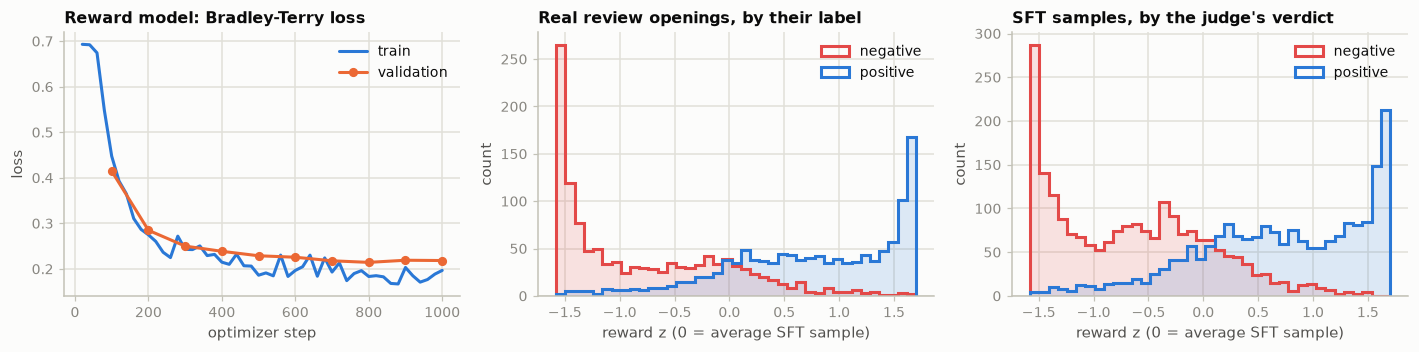

In [9]:
def build_calibration():
    g = torch.Generator().manual_seed(CFG["seed"] + 2)
    prompts = prompt_pool[torch.randint(len(prompt_pool), (CFG["calib_n"],), generator=g)]
    seq, _ = generate(ref, prompts, generator=gen_for(2))
    raw = in_chunks(lambda s: reward_of(rm, s), seq).cpu()
    return {"seq": seq.cpu(), "raw": raw, "judge": judge_prob(seq), "mu": raw.mean().item(), "sigma": raw.std().item()}


calib = cached("calibration", settings_for("sft_", "rm_", "calib_", "judge"), build_calibration)
MU, SIGMA = calib["mu"], calib["sigma"]
with torch.no_grad():                                         # fold the normalization into the head: rm now outputs z
    rm.head.weight.copy_(rm_ck["model"]["head.weight"].to(device) / SIGMA)
    rm.head.bias.copy_((rm_ck["model"]["head.bias"].to(device) - MU) / SIGMA)
calib_z = (calib["raw"] - MU) / SIGMA
calib_pos = calib["judge"] > 0.5
val_z = (rm_ck["val_scores"] - MU) / SIGMA
HUMAN_POS_Z, HUMAN_NEG_Z = val_z[rm_val_is_pos].mean().item(), val_z[~rm_val_is_pos].mean().item()
rm_judge_auc = auc(calib_z, calib_pos)
print(f"SFT samples the judge calls positive: {calib_pos.float().mean():.1%}")
print(f"agreement between reward model and judge on SFT samples (AUC): {rm_judge_auc:.3f}")
print(f"mean reward of real positive openings: {HUMAN_POS_Z:+.2f}   real negative openings: {HUMAN_NEG_Z:+.2f}   SFT samples: 0 by construction")

order = calib_z.argsort()
for title, rows in (("highest reward", order[-3:].flip(0)), ("lowest reward", order[:3])):
    print(f"\n--- SFT samples with the {title}")
    for i in rows.tolist():
        verdict = "positive" if calib_pos[i] else "negative"
        print(textwrap.fill(f"z={calib_z[i]:+.2f} judge={verdict}: {tok.decode(calib['seq'][i, 1:].tolist())}", 118, subsequent_indent="    "))

hist = rm_ck["history"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].plot(hist["step"], hist["train"], color=COLOR["train"], label="train")
axes[0].plot(hist["val_step"], hist["val"], color=COLOR["validation"], marker="o", ms=5, label="validation")
axes[0].set(title="Reward model: Bradley-Terry loss", xlabel="optimizer step", ylabel="loss")
axes[0].legend()
bins = np.linspace(min(val_z.min().item(), calib_z.min().item()), max(val_z.max().item(), calib_z.max().item()), 40)
for ax, scores, mask, what in ((axes[1], val_z, rm_val_is_pos, "Real review openings, by their label"),
                               (axes[2], calib_z, calib_pos, "SFT samples, by the judge's verdict")):
    for name, m in (("negative", ~mask), ("positive", mask)):
        ax.hist(scores[m].numpy(), bins=bins, histtype="stepfilled", color=COLOR[name], alpha=0.15)
        ax.hist(scores[m].numpy(), bins=bins, histtype="step", color=COLOR[name], lw=2, label=name)
    ax.set(title=what, xlabel="reward z (0 = average SFT sample)", ylabel="count")
    ax.legend()
finish(fig, "reward_model")

## 4. PPO

### Text generation as a reinforcement-learning problem

| RL term | Here |
|---|---|
| state $s_t$ | the prompt plus the $t$ tokens written so far |
| action $a_t$ | the next token, one of 50,256 |
| policy $\pi_\theta(a_t \mid s_t)$ | the language model |
| episode | $T = 56$ tokens, always |
| reward | defined next |

### The reward: score minus a KL penalty

Maximizing the reward model's score alone would fail. The reward model is only reliable on text that looks
like reviews, and a policy free to move anywhere would drift into nonsense that happens to score well. RLHF
therefore optimizes

$$R(x) = z(x) \;-\; \beta \sum_{t=0}^{T-1} \log \frac{\pi_\theta(a_t \mid s_t)}{\pi_\text{ref}(a_t \mid s_t)},$$

where $z$ is the normalized reward-model score. The expectation of the sum is
$\mathrm{KL}(\pi_\theta \,\|\, \pi_\text{ref})$ over whole continuations: how far the policy has moved from the
SFT model, in nats. As per-step rewards this is

$$r_t = -\beta \log \frac{\pi_\theta(a_t \mid s_t)}{\pi_\text{ref}(a_t \mid s_t)} \;+\; \mathbb{1}[t = T-1]\; z(x).$$

Every token pays a small price for being more likely under the policy than under the reference, and the last
token also collects the score of the finished text.

**How much may the policy move?** Instead of fixing $\beta$, the notebook fixes a **KL budget** in nats per
sequence and lets $\beta$ adapt: after each iteration $\beta$ goes up if the measured KL is over budget and
down if it is under. A budget is easier to reason about than a coefficient. Two reference points: restricting
a 50/50 policy to its positive half costs $\ln 2 \approx 0.7$ nats, and turning around a prompt that the
reference continues negatively 90% of the time costs $\ln 10 \approx 2.3$ nats.

### Advantages (GAE)

A separate network, the **critic** $V_\psi(s_t)$, predicts the total reward still to come from state $s_t$.
The advantage $\hat{A}_t$ says how much better an action turned out than the critic expected. Generalized
advantage estimation computes it backwards through the episode from one-step surprises $\delta_t$:

$$\delta_t = r_t + \gamma V_\psi(s_{t+1}) - V_\psi(s_t), \qquad \hat{A}_t = \delta_t + \gamma\lambda\,\hat{A}_{t+1},
  \qquad V_\psi(s_T) = 0,$$

with $\gamma = 1$ (the episode is short and the only large reward comes at the end) and $\lambda = 0.95$.
With a good critic, a token is credited only for the *change* in expected outcome it caused, instead of every
token in a sample sharing one number as in REINFORCE.

### The PPO update

A batch of episodes is expensive to collect, so PPO reuses it for several gradient steps. That is only safe
while the policy stays close to the one that collected the data. With the probability ratio
$\rho_t = \pi_\theta(a_t \mid s_t) / \pi_\text{old}(a_t \mid s_t)$, the clipped objective removes any incentive
to move the ratio outside $[1-\epsilon,\, 1+\epsilon]$:

$$\mathcal{L}_\text{policy} = -\,\mathbb{E}_t \min\!\big(\rho_t \hat{A}_t,\; \mathrm{clip}(\rho_t, 1-\epsilon, 1+\epsilon)\,\hat{A}_t\big),
  \qquad \mathcal{L}_\text{critic} = \tfrac12\,\mathbb{E}_t \big(V_\psi(s_t) - \hat{R}_t\big)^2, \quad \hat{R}_t = \hat{A}_t + V_\text{old}(s_t).$$

### Four networks

| Network | Starts from | Trained in this stage? |
|---|---|---|
| policy $\pi_\theta$ | the SFT model | yes |
| reference $\pi_\text{ref}$ | the SFT model | no, frozen |
| reward model $z$ | stage 3 | no, frozen |
| critic $V_\psi$ | the reward model (it already predicts the final score from a full text) | yes |

Dropout is switched off for all of them, so the ratio $\rho_t$ is exactly 1 before the first gradient step.

In [10]:
def gae(rewards, values, gamma, lam):
    """rewards, values: (B, T). The state after the last action is terminal, with value 0."""
    advantages = torch.zeros_like(rewards)
    running = next_value = torch.zeros_like(rewards[:, 0])
    for t in reversed(range(rewards.shape[1])):
        delta = rewards[:, t] + gamma * next_value - values[:, t]
        running = delta + gamma * lam * running
        advantages[:, t] = running
        next_value = values[:, t]
    return advantages, advantages + values


def ppo_train(policy, critic, reward_fn, monitor=None):
    """Improve `policy` against `reward_fn` (sequences -> one score each). Returns the per-iteration log."""
    c = CFG
    B, MB, eps = c["ppo_batch"], c["ppo_minibatch"], c["ppo_clip"]
    policy.eval(), critic.eval()                                # dropout off: the ratio starts at exactly 1
    opt_policy = torch.optim.AdamW(policy.parameters(), lr=c["ppo_policy_lr"], weight_decay=0.0)
    opt_critic = torch.optim.AdamW(critic.parameters(), lr=c["ppo_critic_lr"], weight_decay=0.0)
    g, g_dev = torch.Generator().manual_seed(c["seed"] + 3), gen_for(3)
    beta, log = c["ppo_beta_init"], []
    for it in range(c["ppo_iters"]):
        t0 = time.time()
        # --- 1. rollout: the current policy writes B continuations
        prompts = prompt_pool[torch.randint(len(prompt_pool), (B,), generator=g)]
        seq, logp_sampler = generate(policy, prompts, generator=g_dev)
        with torch.no_grad():
            logp_old = torch.cat([action_logprobs(policy, s)[0] for s in seq.split(MB)])
            logp_ref = torch.cat([action_logprobs(ref, s)[0] for s in seq.split(MB)])
            v_old = torch.cat([values_of(critic, s) for s in seq.split(MB)])
            score = torch.cat([reward_fn(s) for s in seq.split(MB)])
        sampler_gap = (logp_old - logp_sampler).abs().max().item()
        assert sampler_gap < 0.05, f"sampling and scoring disagree by {sampler_gap:.3f} nats: indices are misaligned"

        # --- 2. per-token rewards and advantages
        kl_tokens = logp_old - logp_ref                         # sampled estimate of the KL, one term per token
        rewards = -beta * kl_tokens
        rewards[:, -1] += score                                 # the finished text's score arrives on the last action
        advantages, returns = gae(rewards, v_old, c["ppo_gamma"], c["ppo_lam"])
        adv = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        # --- 3. several epochs of clipped updates on this one batch
        stats, epochs_run = defaultdict(list), 0
        for epoch in range(c["ppo_epochs"]):
            epoch_kl = []
            for mb in torch.randperm(B, generator=g).split(MB):
                mb = mb.to(device)
                logp_new, table = action_logprobs(policy, seq[mb])
                log_ratio = logp_new - logp_old[mb]
                if epoch == 0 and not stats["clip"]:            # nothing has been updated yet in this iteration
                    assert log_ratio.abs().max().item() < 1e-2, "ratio must be 1 before the first step"
                ratio = log_ratio.exp()
                policy_loss = -torch.min(ratio * adv[mb], ratio.clamp(1 - eps, 1 + eps) * adv[mb]).mean()
                opt_policy.zero_grad(set_to_none=True)
                policy_loss.backward()
                norm_policy = torch.nn.utils.clip_grad_norm_(policy.parameters(), c["ppo_grad_clip"])
                opt_policy.step()

                value_loss = 0.5 * (values_of(critic, seq[mb]) - returns[mb]).pow(2).mean()
                opt_critic.zero_grad(set_to_none=True)
                value_loss.backward()
                norm_critic = torch.nn.utils.clip_grad_norm_(critic.parameters(), c["ppo_grad_clip"])
                opt_critic.step()

                with torch.no_grad():
                    table = table.detach()
                    step_kl = (ratio - 1 - log_ratio).mean().item()   # estimate of KL(old || new) per token, always >= 0
                    epoch_kl.append(step_kl)
                    stats["step_kl"].append(step_kl)
                    stats["clip"].append(((ratio - 1).abs() > eps).float().mean().item())
                    stats["entropy"].append(-(table.exp() * table).sum(-1).mean().item())
                    stats["value_loss"].append(value_loss.item())
                    stats["norm_policy"].append(norm_policy.item())
                    stats["norm_critic"].append(norm_critic.item())
                del table
            epochs_run += 1
            if np.mean(epoch_kl) > c["ppo_step_kl"]:            # this batch has been used as far as is safe
                break

        # --- 4. move beta toward the KL budget
        kl = kl_tokens.sum(1).mean().item()                     # nats per sequence
        row = {"it": it, "reward": score.mean().item(), "kl": kl, "beta": beta, "epochs": epochs_run,
               "explained_var": (1 - (returns - v_old).var() / returns.var()).item(), "sampler_gap": sampler_gap,
               **{k: float(np.mean(v)) for k, v in stats.items()}}
        if c["ppo_kl_target"]:
            error = min(max(kl / c["ppo_kl_target"] - 1, -1.0), 1.0)
            beta = min(max(beta * math.exp(c["ppo_beta_rate"] * error), c["ppo_beta_min"]), c["ppo_beta_max"])
        if monitor and (it % c["ppo_eval_every"] == 0 or it == c["ppo_iters"] - 1):
            row.update(monitor(policy, it))
        row["seconds"] = time.time() - t0
        log.append(row)
        print(f"it {it:3d} | reward {row['reward']:+.3f} | KL {kl:5.2f} | beta {row['beta']:.3f} | clip {row['clip']:.3f} "
              f"| stepKL {row['step_kl']:.4f} | EV {row['explained_var']:+.2f} | H {row['entropy']:.2f} "
              f"| {epochs_run} ep | {row['seconds']:.1f}s")
    return log

### Checks before training

Index mistakes in this kind of code do not crash. They quietly train on the wrong thing. These assertions
catch the classic ones:

| Check | What it would catch |
|---|---|
| Log-probs recorded while sampling equal the ones recomputed in a single forward pass | logits and actions shifted against each other; cache bugs |
| Changing the last token leaves every policy log-prob and critic value unchanged, but changes the reward | a position that can see its own future; reward read at the wrong place |
| A hand-computed GAE example | mistakes in the advantage recursion |
| A fresh policy has exactly zero KL to the reference, without sharing memory with it | a stale or aliased reference |

In [11]:
with torch.no_grad():
    check_policy = new_lm(sft_ck["model"])
    seq, logp_sampler = generate(check_policy, dev_prompts[:8], generator=gen_for(9))
    logp, table = action_logprobs(check_policy, seq)
    assert seq.shape == (8, L) and logp.shape == (8, T) and (seq[:, 0] == EOS).all() and (seq[:, 1:] != EOS).all()
    gap = (logp - logp_sampler).abs().max().item()
    assert gap < 0.05, gap

    changed = seq.clone()
    changed[:, -1] = (changed[:, -1] + 1) % EOS
    assert torch.equal(action_logprobs(check_policy, changed)[1], table), "the last token leaked into the policy"
    assert torch.equal(values_of(rm, changed), values_of(rm, seq)), "the last token leaked into the critic"
    assert (reward_of(rm, changed) != reward_of(rm, seq)).all(), "the reward does not read the last token"

    assert (logp - action_logprobs(ref, seq)[0]).abs().max().item() < 1e-5, "a fresh policy must equal the reference"
    assert next(check_policy.parameters()).data_ptr() != next(ref.parameters()).data_ptr()
    del check_policy, table

r = torch.tensor([[0.0, 0.0, 1.0]])
v = torch.tensor([[0.5, 0.2, 0.4]])
a, ret = gae(r, v, gamma=1.0, lam=1.0)                          # lambda = 1: advantage = (sum of future rewards) - V
assert torch.allclose(a, torch.tensor([[0.5, 0.8, 0.6]])) and torch.allclose(ret, torch.ones(1, 3))
a, _ = gae(r, v, gamma=1.0, lam=0.0)                            # lambda = 0: one-step surprises only
assert torch.allclose(a, torch.tensor([[-0.3, 0.2, 0.6]]))
print(f"all checks passed (largest sampling-vs-scoring gap: {gap:.1e} nats)")

all checks passed (largest sampling-vs-scoring gap: 1.1e-04 nats)


### Run PPO

What the columns of the log mean, and what healthy training looks like:

| Column | Meaning | Healthy | Trouble |
|---|---|---|---|
| `reward` | mean reward-model score of the batch, in SFT standard deviations | starts near 0 and climbs, and the judge's positive rate climbs with it | flat (no learning), or climbing while the judge stays flat (the reward model is being gamed) |
| `KL` | distance from the SFT model, nats per sequence | rises to the budget and stays near it | far over budget for many iterations |
| `beta` | current KL coefficient | settles | pinned at its minimum or maximum |
| `clip` | fraction of tokens whose ratio left $[1-\epsilon, 1+\epsilon]$ | a few percent to 20% | above 30% (steps too large), or 0 with a flat reward |
| `stepKL` | how far one iteration's update moved the policy, per token | well under 0.02 | every iteration stopped after one epoch |
| `EV` | explained variance of the critic: 1 is perfect, 0 is no better than a constant | positive and rising | at or below 0 |
| `H` | policy entropy, nats per token | falls slowly | collapses (the policy repeats itself) |

The cell rebuilds the policy from the saved SFT checkpoint every time it runs, so running it twice never
continues from the first run's weights.

In [12]:
def fingerprint(module):
    return sum(p.detach().cpu().double().abs().sum().item() for p in module.parameters())


def dev_monitor(policy, it):
    seq, _ = generate(policy, dev_prompts, generator=gen_for(11))
    z = in_chunks(lambda s: reward_of(rm, s), seq).mean().item()
    judged = (judge_prob(seq) > 0.5).float().mean().item()
    print(f"    held-out prompts: reward {z:+.3f}, judge says positive {judged:.1%}")
    for row in seq[[0, len(seq) // 2, 1]].tolist():
        print(textwrap.fill(f"    [{tok.decode(row[1:1 + P])}]{tok.decode(row[1 + P:])}", 118, subsequent_indent="      "))
    return {"dev_reward": z, "dev_judge": judged}


def warm_up_critic(critic):
    """Before PPO the policy equals the reference, so the return from every step is just the final score z."""
    opt = torch.optim.AdamW(critic.parameters(), lr=CFG["ppo_critic_lr"], weight_decay=0.0)
    g = torch.Generator().manual_seed(CFG["seed"] + 4)
    for epoch in range(CFG["ppo_critic_warmup_epochs"]):
        losses = []
        for mb in torch.randperm(len(calib_z), generator=g).split(CFG["ppo_minibatch"]):
            values = values_of(critic, calib["seq"][mb].to(device))
            loss = 0.5 * (values - calib_z[mb].to(device)[:, None]).pow(2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(critic.parameters(), CFG["ppo_grad_clip"])
            opt.step()
            losses.append(loss.item())
        print(f"critic warm-up epoch {epoch + 1}: value loss {np.mean(losses):.3f} (predicting a constant gives 0.5)")


def build_ppo():
    policy = new_lm(sft_ck["model"])                            # always from disk
    critic = ScalarGPT().to(device)
    critic.load_state_dict(rm.state_dict())                     # the normalized reward model
    critic.eval()
    warm_up_critic(critic)
    before = fingerprint(ref), fingerprint(rm)
    log = ppo_train(policy, critic, lambda s: reward_of(rm, s), monitor=dev_monitor)
    assert (fingerprint(ref), fingerprint(rm)) == before, "a frozen network changed during PPO"
    assert abs(log[0]["kl"]) < 1e-3, "the first rollout must come from the reference policy itself"
    return {"model": cpu_state(policy), "log": log}


ppo_ck = cached("ppo", settings_for("sft_", "rm_", "calib_", "judge", "ppo_"), build_ppo)
log = pd.DataFrame(ppo_ck["log"])
log.to_json(OUT / "ppo_log.json", orient="records", indent=1)
policy = new_lm(ppo_ck["model"])

critic warm-up epoch 1: value loss 0.157 (predicting a constant gives 0.5)


critic warm-up epoch 2: value loss 0.139 (predicting a constant gives 0.5)


    held-out prompts: reward +0.309, judge says positive 62.5%
    [Princess Warrior is a science fiction action]-drama from 1996 (and before that) which often resembles the
      espionage genre of War and Peace but in many ways in fits really nicely. Although it tries IMHO, it is social
      commentary which is not always completely gorgeous, especially on space. The contemplative character of the
    [Dario Argento is a filmmaker I]'ve always admired. I photographed on cinephile radio in my neighborhood. On the
      right we have Ernesto Trujillo, the actor from Columbia Pictures; the left is Douglas Turner, the director
      professor of music at Queen Charlotte University; the right is Leatherface's director
    [This...... Movie.... Is..... Horrible]. Sci-Fi Legend Throug Kipling's Bad Angel Chapter has 8 stitches in its
      waist - indeed MORE than any other TOOE JOE EVER!!! Emilio is amputated by the Devil during a hurricane,
      poisoning everyone and everyone not heale

it   1 | reward +0.324 | KL  0.30 | beta 0.082 | clip 0.057 | stepKL 0.0047 | EV +0.88 | H 3.58 | 4 ep | 15.7s


it   2 | reward +0.694 | KL  1.36 | beta 0.068 | clip 0.048 | stepKL 0.0042 | EV +0.84 | H 3.45 | 4 ep | 16.6s


it   3 | reward +0.901 | KL  2.75 | beta 0.058 | clip 0.040 | stepKL 0.0035 | EV +0.88 | H 3.39 | 4 ep | 15.7s


... (53 outputs left out)

it  57 | reward +1.554 | KL  5.59 | beta 0.047 | clip 0.035 | stepKL 0.0034 | EV +0.82 | H 3.40 | 4 ep | 15.7s


it  58 | reward +1.556 | KL  5.79 | beta 0.047 | clip 0.028 | stepKL 0.0028 | EV +0.85 | H 3.39 | 4 ep | 15.7s


    held-out prompts: reward +1.523, judge says positive 100.0%
    [Princess Warrior is a science fiction action]-drama from 1996 that features the best acting of the year.
      Featuring Clive Owen as a ruthless Wolverine trying to mend house, Chris Hemsworth as a battle-hardened
      abominable Troll warrior, and Brandi deLornay as her more contemplative pick. Truly
    [Dario Argento is a filmmaker I]'ve always admired. I photographed on cams, in post matches, among a network of
      well known companies, as he was about to catch a flight. I love the technique that his cameras capture the
      essence of those moments simultaneously manically and subconsciously in the mundane. The film
    [This...... Movie.... Is..... Horrible]. But for those who enjoy this movie, be a little more patient and
      appreciate Shakespeare's many important works. MORE SCENE TIME TO TELL YOU About The Car... is a wonderful Movie
      for people who enjoy an insightful film about these classic no

[ppo] done in 16.8 min, saved to out/ppo.pt


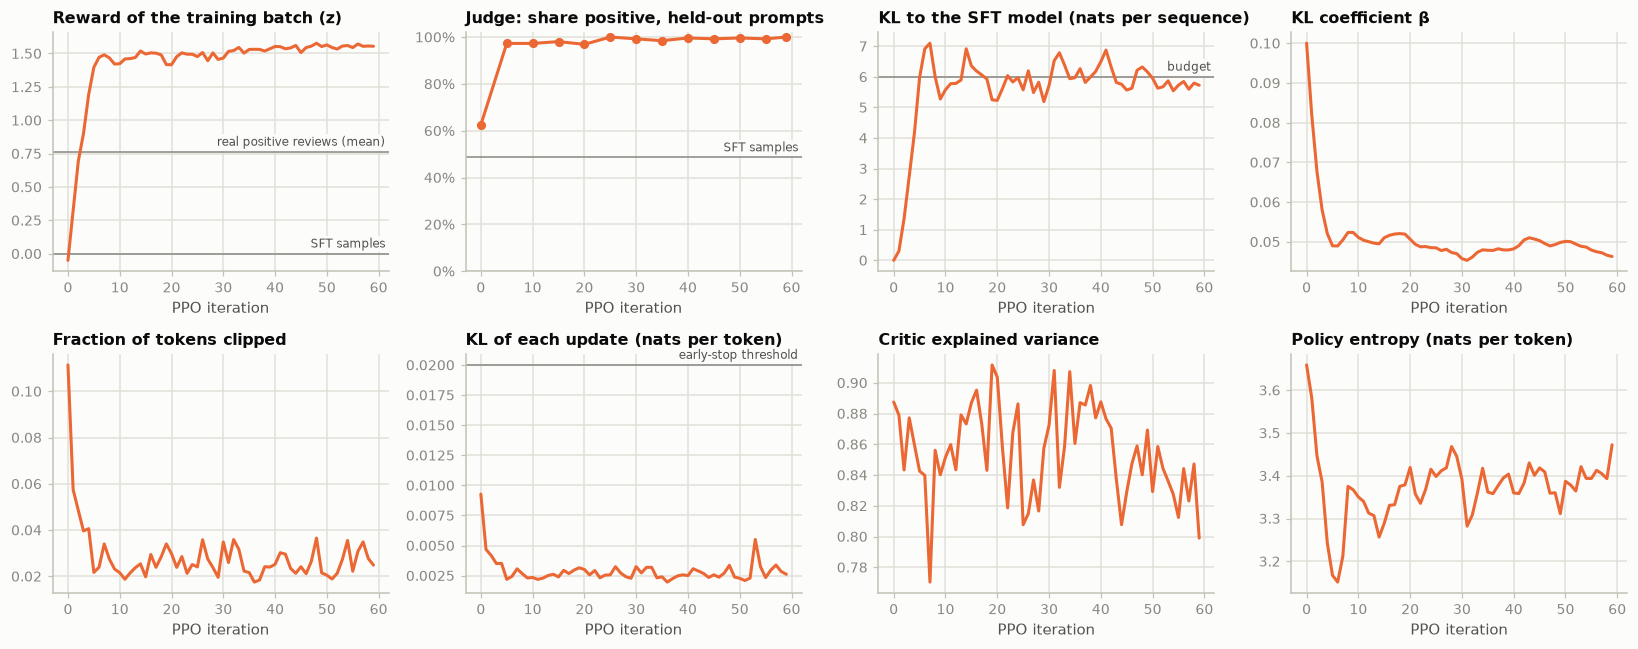

In [13]:
panels = [("reward", "Reward of the training batch (z)"), ("dev_judge", "Judge: share positive, held-out prompts"),
          ("kl", "KL to the SFT model (nats per sequence)"), ("beta", "KL coefficient β"),
          ("clip", "Fraction of tokens clipped"), ("step_kl", "KL of each update (nats per token)"),
          ("explained_var", "Critic explained variance"), ("entropy", "Policy entropy (nats per token)")]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, (key, title) in zip(axes.flat, panels):
    series = log[["it", key]].dropna()
    ax.plot(series["it"], series[key], color=COLOR["PPO"], marker="o" if key == "dev_judge" else None, ms=5)
    ax.set(title=title, xlabel="PPO iteration")
reference_line(axes[0, 0], HUMAN_POS_Z, "real positive reviews (mean)")
reference_line(axes[0, 0], 0.0, "SFT samples")
reference_line(axes[0, 1], calib_pos.float().mean().item(), "SFT samples")
axes[0, 1].set_ylim(0, 1.02)
axes[0, 1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
if CFG["ppo_kl_target"]:
    reference_line(axes[0, 2], CFG["ppo_kl_target"], "budget")
reference_line(axes[1, 1], CFG["ppo_step_kl"], "early-stop threshold")
finish(fig, "ppo")

## 5. Evaluation

Everything here uses the 2,000 held-out prompts from the `test` split (half taken from negative reviews, half
from positive ones). Each model writes one continuation per prompt with the same random seed. Four rows are
compared:

- **Human**: the real openings of those reviews, for scale.
- **GPT-2**: the pretrained model before any training in this notebook.
- **SFT**: after fine-tuning. This is where PPO started.
- **PPO**: the final policy.

| Column | What it tells you |
|---|---|
| reward z | the reward model's score, the quantity PPO optimized |
| judge positive | share of texts the independent judge calls positive. PPO never saw the judge. |
| ... from negative / positive | the same, split by the sentiment of the review the prompt came from. Prompts from negative reviews are the hard case: the policy has to turn the text around. |
| KL to SFT | how far the model's distribution is from the SFT model, nats per sequence |
| SFT NLL | how surprising the text is to the SFT model, nats per token. Much higher than the SFT row means unnatural text. Much lower means safe, generic text. |
| distinct-1 / distinct-2 | unique words and word pairs divided by the total: vocabulary diversity across all continuations |
| repeats | share of word pairs within a continuation that already appeared earlier in it |

Intervals are 95% bootstrap intervals over prompts.

Two things to check beyond the headline. First, compare the PPO row's reward with the Human row and with the
ceiling seen in stage 3: a policy that optimizes a score ends up writing *unmistakable* praise, more uniformly
positive than real positive reviews are. Second, read the last four columns against the SFT row. That is
where the price of the improvement shows: how far the policy moved, and how much variety it gave up.

In [14]:
boot_rng = np.random.default_rng(CFG["seed"])


def mean_ci(x):
    x = np.asarray(x, dtype=np.float64)
    means = x[boot_rng.integers(0, len(x), (CFG["eval_boot"], len(x)))].mean(1)
    return x.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


def fmt(x, pct=False):
    m, lo, hi = mean_ci(x)
    return f"{m:.1%} [{lo:.1%}, {hi:.1%}]" if pct else f"{m:+.2f} [{lo:+.2f}, {hi:+.2f}]"


def distinct(cont, n):
    grams = np.lib.stride_tricks.sliding_window_view(cont, n, axis=1).reshape(-1, n)
    return len(np.unique(grams, axis=0)) / len(grams)


def measure(seq, lm=None):
    """Per-sequence measurements for one set of texts. `lm` is the model that wrote them (None for human text)."""
    cont = seq[:, 1 + P:].cpu().numpy()
    logp_ref = in_chunks(lambda s: action_logprobs(ref, s)[0], seq, 128)
    judge_p = judge_prob(seq).numpy()
    out = {"z": in_chunks(lambda s: reward_of(rm, s), seq).cpu().numpy(),
           "judge": (judge_p > 0.5).astype(float), "judge_p": judge_p,
           "ref_nll": (-logp_ref.mean(1)).cpu().numpy(),
           "repeat": np.array([1 - len(set(zip(r[:-1], r[1:]))) / (len(r) - 1) for r in cont]),
           "distinct1": distinct(cont, 1), "distinct2": distinct(cont, 2), "seq": seq.cpu()}
    if lm is not None:
        logp_self = in_chunks(lambda s: action_logprobs(lm, s)[0], seq, 128)
        out["kl"] = (logp_self - logp_ref).sum(1).cpu().numpy()
    return out


t0 = time.time()
gpt2 = new_lm()
models = {"GPT-2": gpt2, "SFT": ref, "PPO": policy}
results = {"Human": measure(eval_seq.to(device))}
for name, lm in models.items():
    seq, _ = generate(lm, eval_prompts, generator=gen_for(100))  # the same random stream for every model
    results[name] = measure(seq, lm)
del gpt2
TIMES["evaluation"] = time.time() - t0

from_neg, from_pos = (eval_label == 0).numpy(), (eval_label == 1).numpy()
table = pd.DataFrame({
    name: {"reward z": fmt(r["z"]),
           "judge positive": fmt(r["judge"], pct=True),
           "... from negative": fmt(r["judge"][from_neg], pct=True),
           "... from positive": fmt(r["judge"][from_pos], pct=True),
           "KL to SFT": f"{r['kl'].mean():.2f}" if "kl" in r else "–",
           "SFT NLL": f"{r['ref_nll'].mean():.2f}",
           "distinct-1": f"{r['distinct1']:.3f}", "distinct-2": f"{r['distinct2']:.3f}",
           "repeats": f"{r['repeat'].mean():.1%}"}
    for name, r in results.items()}).T
show_table(table)

ppo, sft = results["PPO"], results["SFT"]
win_rm, win_judge = ppo["z"] > sft["z"], ppo["judge_p"] > sft["judge_p"]
print(f"\nOn the same prompt, PPO's continuation beats SFT's according to the reward model: {fmt(win_rm, pct=True)}")
print(f"On the same prompt, PPO's continuation beats SFT's according to the judge:        {fmt(win_judge, pct=True)}")

,reward z,judge positive,... from negative,... from positive,KL to SFT,SFT NLL,distinct-1,distinct-2,repeats
Human,"+0.01 [-0.04, +0.06]","49.5% [47.3%, 51.6%]","19.5% [17.1%, 21.9%]","79.5% [77.2%, 82.0%]",–,3.58,0.117,0.564,1.9%
GPT-2,"+0.13 [+0.09, +0.16]","49.0% [46.9%, 51.2%]","38.6% [35.5%, 41.7%]","59.5% [56.5%, 62.6%]",16.04,4.31,0.156,0.675,1.7%
SFT,"-0.01 [-0.05, +0.03]","47.9% [45.6%, 49.9%]","38.6% [35.5%, 41.6%]","57.1% [54.1%, 60.1%]",0.00,3.73,0.124,0.599,1.4%
PPO,"+1.54 [+1.53, +1.55]","99.2% [98.7%, 99.6%]","98.9% [98.2%, 99.5%]","99.4% [98.9%, 99.8%]",5.50,3.55,0.106,0.525,1.8%



On the same prompt, PPO's continuation beats SFT's according to the reward model: 96.4% [95.5%, 97.2%]
On the same prompt, PPO's continuation beats SFT's according to the judge:        93.5% [92.5%, 94.5%]


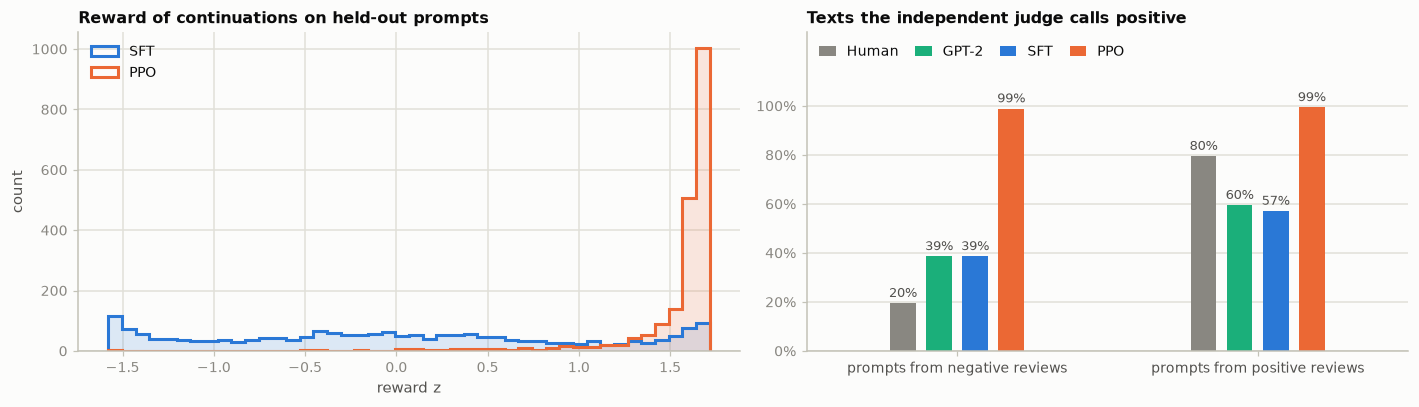

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
bins = np.linspace(min(sft["z"].min(), ppo["z"].min()), max(sft["z"].max(), ppo["z"].max()), 45)
for name in ("SFT", "PPO"):
    ax.hist(results[name]["z"], bins=bins, histtype="stepfilled", color=COLOR[name], alpha=0.15)
    ax.hist(results[name]["z"], bins=bins, histtype="step", color=COLOR[name], lw=2, label=name)
ax.set(title="Reward of continuations on held-out prompts", xlabel="reward z", ylabel="count")
ax.legend()

ax = axes[1]
names, width = list(results), 0.085
for i, name in enumerate(names):
    heights = [results[name]["judge"][from_neg].mean(), results[name]["judge"][from_pos].mean()]
    xs = np.arange(2) + (i - (len(names) - 1) / 2) * (width + 0.035)
    ax.bar(xs, heights, width=width, color=COLOR[name], label=name)
    for x, y in zip(xs, heights):
        ax.annotate(f"{y:.0%}", (x, y), ha="center", va="bottom", fontsize=8.5, color=INK2, xytext=(0, 2), textcoords="offset points")
ax.set_xticks(np.arange(2), ["prompts from negative reviews", "prompts from positive reviews"])
ax.tick_params(axis="x", labelcolor=INK2)
ax.set(title="Texts the independent judge calls positive", ylim=(0, 1.3), xlim=(-0.5, 1.5), yticks=np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(ncols=4, loc="upper left", columnspacing=1.2, handlelength=1.2)
finish(fig, "evaluation")

### Reading the outputs

Numbers can hide a policy that found a cheap trick, so the last two cells show the text itself.

**Which words did PPO start to favor?** The tokens whose frequency grew most between the SFT and PPO
continuations. In `minimal-rlhf` this list would have been one word, "loved". A healthy result is a spread of
ordinary positive vocabulary. A handful of tokens with enormous counts would mean the policy collapsed onto
them.

**Same prompt, two models.** Continuations of the same prompts by the SFT model and by the PPO policy, with
the reward-model score and the judge's verdict for each.

In [16]:
vocab = len(tok)
count_sft = np.bincount(sft["seq"][:, 1 + P:].flatten().numpy(), minlength=vocab) + 1.0
count_ppo = np.bincount(ppo["seq"][:, 1 + P:].flatten().numpy(), minlength=vocab) + 1.0
log_odds = np.log(count_ppo / count_ppo.sum()) - np.log(count_sft / count_sft.sum())
log_odds[count_ppo < max(5, len(eval_seq) // 100)] = -np.inf     # ignore rare tokens
top = np.argsort(-log_odds)[:20]
print("tokens that became more frequent under PPO (count in PPO texts / count in SFT texts):")
print(textwrap.fill("   ".join(f"{tok.decode([i])!r} {int(count_ppo[i] - 1)}/{int(count_sft[i] - 1)}" for i in top), 118))
top_share = (np.sort(count_ppo - 1)[::-1][:5].sum() / (count_ppo - 1).sum(), np.sort(count_sft - 1)[::-1][:5].sum() / (count_sft - 1).sum())
print(f"\nshare of all generated tokens taken by the five most common tokens: PPO {top_share[0]:.1%}, SFT {top_share[1]:.1%}")


def describe(r, i):
    verdict = "positive" if r["judge"][i] else "negative"
    return f"(z={r['z'][i]:+.2f}, judge: {verdict}) {tok.decode(r['seq'][i, 1 + P:].tolist()).strip()}"


h = len(eval_seq) // 2
for i in [0, 1, 2, 3, h, h + 1, h + 2, h + 3]:
    source = "negative" if eval_label[i] == 0 else "positive"
    print(f"\nPROMPT (from a {source} review): {tok.decode(eval_seq[i, 1:1 + P].tolist())!r}")
    for name in ("SFT", "PPO"):
        print(textwrap.fill(f"  {name}: {describe(results[name], i)}", 118, subsequent_indent="       "))

tokens that became more frequent under PPO (count in PPO texts / count in SFT texts):
' beautifully' 69/7   ' captures' 25/2   ' extraordinary' 23/2   ' historical' 22/2   ' stunning' 50/6   ' wonderful'
192/26   ' rive' 27/3   ' brilliant' 110/15   ' fantastic' 82/11   ' awesome' 40/5   'ting' 26/3   ' wonderfully' 26/3
' Everything' 23/3   ' incredible' 53/8   ' superb' 116/19   ' Great' 22/3   ' unique' 73/12   ' perfect' 101/17   '
truly' 151/26   ' compelling' 31/5

share of all generated tokens taken by the five most common tokens: PPO 17.5%, SFT 15.1%

PROMPT (from a negative review): 'Believe it or not, this was'
  SFT: (z=-1.49, judge: negative) once very successful. Now it's virtually extinct. There's no writing, no history,
       nothing aesthetically interesting, no acting...Except for the fact that there's a flyer on the wall half a
       miles from MGM Studio 3. I suspect the movie was supposed to broadcast the terrible
  PPO: (z=+1.68, judge: positive) my very first mo

In [17]:
summary = {
    "settings": CFG, "smoke": SMOKE, "device": device,
    "seconds": {k: round(v, 1) for k, v in TIMES.items()},
    "sft_val_loss": {"pretrained": sft_ck["history"]["val"][0], "fine_tuned": sft_ck["history"]["val"][-1]},
    "reward_model_val_pair_accuracy": rm_val_acc,
    "judge_accuracy_on_human_openings": judge_acc,
    "reward_model_vs_judge_auc_on_sft_samples": rm_judge_auc,
    "human_reward_z": {"positive": HUMAN_POS_Z, "negative": HUMAN_NEG_Z},
    "rows": {name: {"reward_z": mean_ci(r["z"]), "judge_positive": mean_ci(r["judge"]),
                    "judge_positive_neg_prompts": mean_ci(r["judge"][from_neg]),
                    "judge_positive_pos_prompts": mean_ci(r["judge"][from_pos]),
                    "kl_to_sft": float(r["kl"].mean()) if "kl" in r else None, "sft_nll": float(r["ref_nll"].mean()),
                    "distinct1": r["distinct1"], "distinct2": r["distinct2"], "repeats": float(r["repeat"].mean())}
             for name, r in results.items()},
    "ppo_beats_sft": {"reward_model": mean_ci(win_rm), "judge": mean_ci(win_judge)},
    "final_beta": float(log["beta"].iloc[-1]), "final_kl": float(log["kl"].iloc[-1]),
}
(OUT / "results.json").write_text(json.dumps(summary, indent=1, default=float))
print("stage times (min):", {k: round(v / 60, 1) for k, v in TIMES.items()})
print(f"results written to {(OUT / 'results.json').relative_to(ROOT)}")

stage times (min): {'data': 0.4, 'sft': 6.4, 'reward_model': 1.9, 'calibration': 0.2, 'ppo': 16.8, 'evaluation': 0.7}
results written to out/results.json


## 6. Wrap-up

### Limitations

- **The preferences are simulated.** Real RLHF collects comparisons between *model outputs* from annotators.
  Here the comparisons come from labels that review authors gave their own text. The reward model, the loss
  and everything downstream are the real thing, but the "human feedback" is a stand-in.
- **Fixed-length episodes.** The policy always writes exactly 56 tokens and never learns when to stop.
- **One seed.** PPO runs differ from seed to seed. A careful comparison would repeat the run several times.
- **A small, well-defined target.** "Be positive" is easy to learn and easy to check. Preferences such as
  "be helpful" need far more data and are far harder to evaluate.
- **The policy optimizes the score, not the intent.** It learns to write the kind of text the reward model
  rates highest, which is emphatic praise on every prompt. The KL budget is the dial that limits this
  (exercise 4).

### Exercises

1. **Remove the KL penalty.** Set `ppo_kl_target=None` and `ppo_beta_init=0.0`. Watch the reward-model score
   climb past the score of real positive reviews while the judge, the SFT NLL and the diversity columns show
   what the text turned into.
2. **Policy gradient without PPO.** Set `ppo_epochs=1`, `ppo_minibatch=ppo_batch` and `ppo_clip=1e9`: one
   unclipped step per batch, the kind of update `minimal-rlhf` used. Compare the reward after the same number
   of sampled episodes.
3. **Reranking instead of RL.** For each prompt, sample 16 continuations from the SFT model and keep the one
   the reward model likes best. How close does that get to PPO, and what does it cost at generation time?
4. **Tighter and looser budgets.** Try `ppo_kl_target` of 2 and 12 and plot judge-positive rate against KL.
5. **Noisy annotators.** Flip the preferred side in 20% of the reward-model pairs and see how much accuracy
   and the final policy suffer.
6. **Episodes that end.** Put `<|endoftext|>` back into the action space, fine-tune on whole short reviews,
   and add a mask so tokens after the end get no reward or gradient.